In [1]:
import os
import glob
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve
import seaborn as sns

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing on compute device: {device}")

Executing on compute device: cuda


In [2]:
MAX_PER_CLASS = 1000
target_classes = ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']

# 1. Quick location discovery
found_class_dirs = {}
for root, dirs, _ in os.walk('/kaggle/input'):
    for d in dirs:
        for cls_name in target_classes:
            if d.lower().replace("_", " ") == cls_name.lower().replace("_", " "):
                if cls_name not in found_class_dirs:
                    found_class_dirs[cls_name] = os.path.join(root, d)
    if len(found_class_dirs) == len(target_classes):
        break

all_image_paths = []
all_labels = []

# 2. Extract balanced subset
for cls_idx, cls_name in enumerate(target_classes):
    folder_path = found_class_dirs.get(cls_name)
    if not folder_path:
        continue

    valid_files = []
    with os.scandir(folder_path) as it:
        for entry in it:
            if entry.is_file() and entry.name.lower().endswith(('.jpg', '.jpeg', '.png')):
                valid_files.append(entry.path)
    
    random.shuffle(valid_files)
    selected = valid_files[:MAX_PER_CLASS]
    print(f"Class: '{cls_name}' | Discovered: {len(valid_files)} | Selected: {len(selected)}")
    all_image_paths.extend(selected)
    all_labels.extend([cls_idx] * len(selected))

# 3. Stratified 70/15/15 Splitting
train_paths, val_test_paths, train_y, val_test_y = train_test_split(
    all_image_paths, all_labels, test_size=0.30, stratify=all_labels, random_state=42
)
val_paths, test_paths, val_y, test_y = train_test_split(
    val_test_paths, val_test_y, test_size=0.50, stratify=val_test_y, random_state=42
)

# Balanced inverse class weights
class_counts = np.bincount(train_y, minlength=len(target_classes))
class_weights = torch.tensor(len(train_y) / (len(target_classes) * class_counts), dtype=torch.float).to(device)
print(f"\nSplit summary -> Train: {len(train_paths)}, Val: {len(val_paths)}, Test: {len(test_paths)}")
print(f"Applied Class Penalties: {class_weights.cpu().numpy().round(3)}")

Class: 'Mild Dementia' | Discovered: 5002 | Selected: 1000
Class: 'Moderate Dementia' | Discovered: 488 | Selected: 488
Class: 'Non Demented' | Discovered: 67222 | Selected: 1000
Class: 'Very mild Dementia' | Discovered: 13725 | Selected: 1000

Split summary -> Train: 2441, Val: 523, Test: 524
Applied Class Penalties: [0.872 1.79  0.872 0.872]


In [3]:
IMAGE_SIZE = 224
BATCH_SIZE = 32

train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class OASISDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        return self.transform(img), torch.tensor(self.labels[idx], dtype=torch.long)

train_loader = DataLoader(OASISDataset(train_paths, train_y, train_transforms), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(OASISDataset(val_paths, val_y, eval_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(OASISDataset(test_paths, test_y, eval_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [4]:
class SwinClassifier(nn.Module):
    def __init__(self, num_classes=4, dropout=0.2, pretrained=True):
        super().__init__()
        weights = models.Swin_T_Weights.DEFAULT if pretrained else None
        self.swin = models.swin_t(weights=weights)
        
        # Swin-T features output dimension is 768
        in_features = self.swin.head.in_features
        self.swin.head = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(in_features, 128),
            nn.GELU(),
            nn.Dropout(p=dropout / 2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.swin(x)

In [5]:
!pip install -q optuna

import optuna
from optuna.pruners import SuccessiveHalvingPruner

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    lr = trial.suggest_float("lr", 3e-5, 3e-4, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-4, 1e-2, log=True)
    dropout = trial.suggest_float("dropout", 0.1, 0.3, step=0.1)
    
    trial_model = SwinClassifier(num_classes=4, dropout=dropout, pretrained=True).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
    optimizer = torch.optim.AdamW(trial_model.parameters(), lr=lr, weight_decay=weight_decay)
    
    TRIAL_EPOCHS = 4
    for epoch in range(TRIAL_EPOCHS):
        trial_model.train()
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = trial_model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(trial_model.parameters(), 1.0)
            optimizer.step()
            
        trial_model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = trial_model(imgs)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)
                
        val_acc = (val_correct / val_total) * 100
        trial.report(val_acc, step=epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()
            
    return val_acc

print("Launching Swin Hyperparameter Sweep...")
study = optuna.create_study(
    direction="maximize",
    pruner=SuccessiveHalvingPruner(min_resource=2, reduction_factor=2)
)
study.optimize(objective, n_trials=8, timeout=360)

print(f"Best Validation Accuracy: {study.best_value:.2f}%")
print("Optimal Configuration:", study.best_params)

Launching Swin Hyperparameter Sweep...
Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 206MB/s]  


Best Validation Accuracy: 80.31%
Optimal Configuration: {'lr': 0.00016368306930509882, 'weight_decay': 0.003170054318977517, 'dropout': 0.1}


In [6]:
best_cfg = study.best_params
print(f"Training full Swin model with: {best_cfg}")

model = SwinClassifier(num_classes=4, dropout=best_cfg['dropout'], pretrained=True).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
optimizer = torch.optim.AdamW(
    model.parameters(), 
    lr=best_cfg['lr'], 
    weight_decay=best_cfg['weight_decay']
)

EPOCHS = 15
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        running_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
    scheduler.step()
    train_loss = running_loss / total
    train_acc = (correct / total) * 100

    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = (val_correct / val_total) * 100

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}%")

Training full Swin model with: {'lr': 0.00016368306930509882, 'weight_decay': 0.003170054318977517, 'dropout': 0.1}
Epoch [01/15] | Train Loss: 1.2017 Acc: 43.71% | Val Loss: 0.8905 Acc: 60.99%
Epoch [02/15] | Train Loss: 0.8556 Acc: 65.06% | Val Loss: 0.7811 Acc: 68.45%
Epoch [03/15] | Train Loss: 0.7479 Acc: 70.87% | Val Loss: 0.6889 Acc: 71.13%
Epoch [04/15] | Train Loss: 0.6373 Acc: 77.30% | Val Loss: 0.5274 Acc: 83.37%
Epoch [05/15] | Train Loss: 0.5701 Acc: 81.28% | Val Loss: 0.5173 Acc: 84.13%
Epoch [06/15] | Train Loss: 0.5077 Acc: 84.88% | Val Loss: 0.6425 Acc: 78.20%
Epoch [07/15] | Train Loss: 0.4601 Acc: 87.67% | Val Loss: 0.6171 Acc: 79.73%
Epoch [08/15] | Train Loss: 0.4061 Acc: 90.91% | Val Loss: 0.4203 Acc: 89.10%
Epoch [09/15] | Train Loss: 0.3695 Acc: 92.26% | Val Loss: 0.4306 Acc: 88.15%
Epoch [10/15] | Train Loss: 0.3609 Acc: 93.36% | Val Loss: 0.4117 Acc: 90.82%
Epoch [11/15] | Train Loss: 0.3238 Acc: 94.76% | Val Loss: 0.4565 Acc: 88.72%
Epoch [12/15] | Train Loss

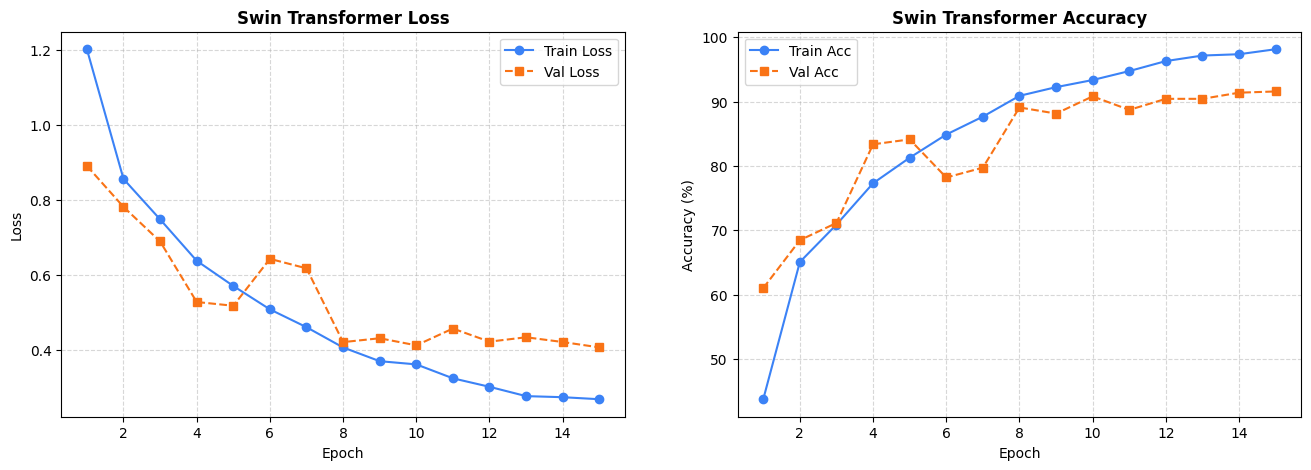

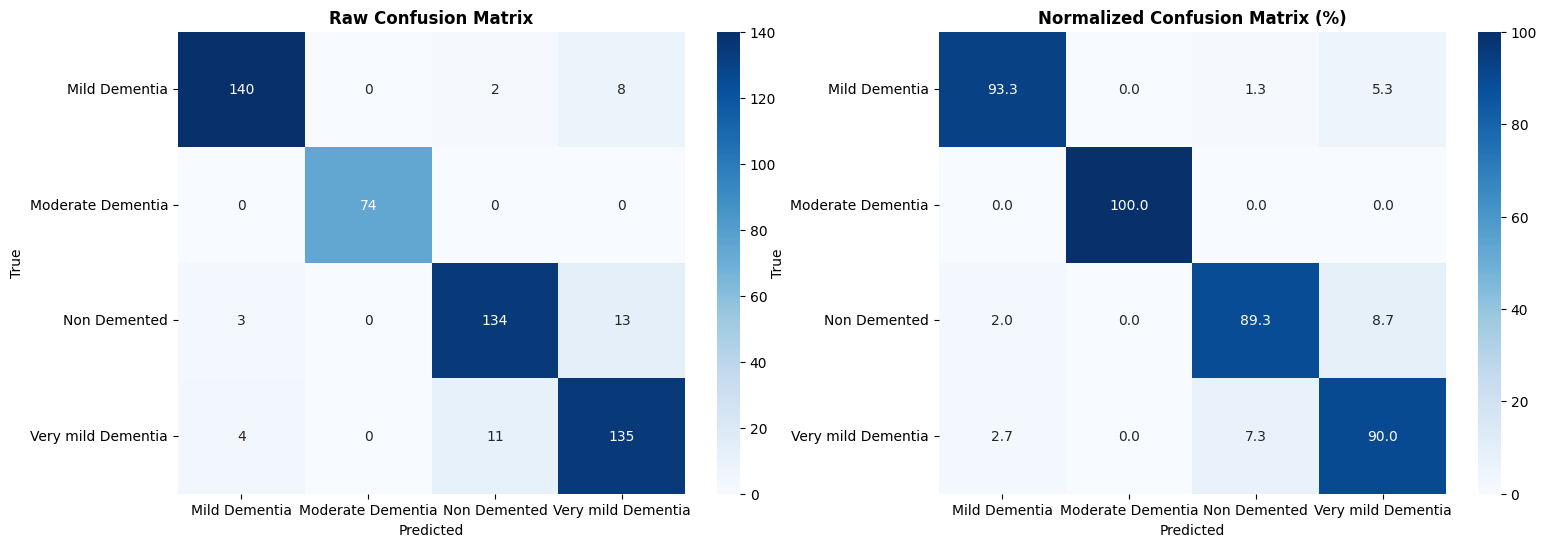

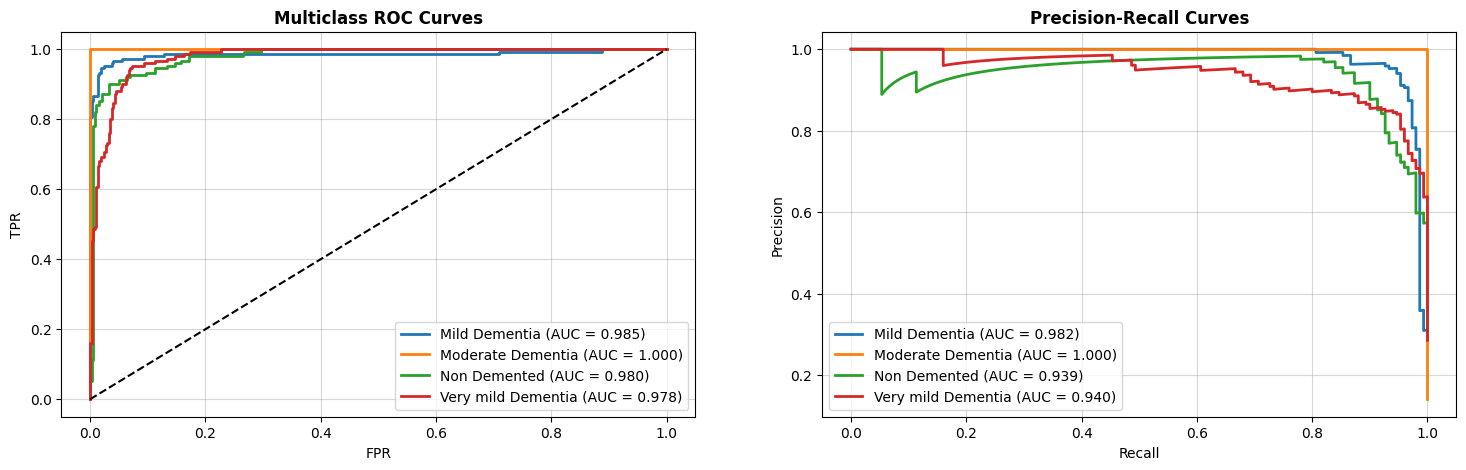

In [7]:
model.eval()
all_preds, all_probs, true_labels = [], [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        probs = F.softmax(outputs, dim=1)
        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(torch.argmax(probs, dim=1).cpu().numpy())
        true_labels.extend(labels.numpy())

all_probs = np.array(all_probs)
all_preds = np.array(all_preds)
true_labels = np.array(true_labels)

# 1. Training & Validation Dynamics
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].plot(range(1, EPOCHS + 1), history['train_loss'], 'o-', label='Train Loss', color='#3b82f6')
ax[0].plot(range(1, EPOCHS + 1), history['val_loss'], 's--', label='Val Loss', color='#f97316')
ax[0].set_title('Swin Transformer Loss', fontweight='bold')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss'); ax[0].grid(True, linestyle='--', alpha=0.5); ax[0].legend()

ax[1].plot(range(1, EPOCHS + 1), history['train_acc'], 'o-', label='Train Acc', color='#3b82f6')
ax[1].plot(range(1, EPOCHS + 1), history['val_acc'], 's--', label='Val Acc', color='#f97316')
ax[1].set_title('Swin Transformer Accuracy', fontweight='bold')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy (%)'); ax[1].grid(True, linestyle='--', alpha=0.5); ax[1].legend()
plt.show()

# 2. Confusion Matrices
cm_raw = confusion_matrix(true_labels, all_preds)
cm_norm = cm_raw.astype('float') / cm_raw.sum(axis=1)[:, np.newaxis] * 100

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
sns.heatmap(cm_raw, annot=True, fmt='d', cmap='Blues', xticklabels=target_classes, yticklabels=target_classes, ax=ax[0])
ax[0].set_title('Raw Confusion Matrix', fontweight='bold')
ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('True')

sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues', xticklabels=target_classes, yticklabels=target_classes, ax=ax[1])
ax[1].set_title('Normalized Confusion Matrix (%)', fontweight='bold')
ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('True')
plt.show()

# 3. Multiclass ROC & Precision-Recall Curves
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for i, cls_name in enumerate(target_classes):
    binary_y = (true_labels == i).astype(int)
    fpr, tpr, _ = roc_curve(binary_y, all_probs[:, i])
    ax[0].plot(fpr, tpr, color=colors[i], lw=2, label=f'{cls_name} (AUC = {auc(fpr, tpr):.3f})')
    
    precision, recall, _ = precision_recall_curve(binary_y, all_probs[:, i])
    ax[1].plot(recall, precision, color=colors[i], lw=2, label=f'{cls_name} (AUC = {auc(recall, precision):.3f})')

ax[0].plot([0, 1], [0, 1], 'k--', lw=1.5)
ax[0].set_title('Multiclass ROC Curves', fontweight='bold')
ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(); ax[0].grid(True, alpha=0.5)

ax[1].set_title('Precision-Recall Curves', fontweight='bold')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend(); ax[1].grid(True, alpha=0.5)
plt.show()

In [8]:
import torch
import numpy as np

# Set model to evaluation mode
model.eval()

test_correct = 0
test_total = 0
class_correct = [0] * len(target_classes)
class_total = [0] * len(target_classes)

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        
        # Overall counts
        test_total += labels.size(0)
        test_correct += (preds == labels).sum().item()
        
        # Per-class breakdown
        for label, pred in zip(labels, preds):
            if label == pred:
                class_correct[label.item()] += 1
            class_total[label.item()] += 1

# Calculate final percentages
overall_accuracy = (test_correct / test_total) * 100

print("=" * 45)
print(f"OVERALL TEST ACCURACY: {overall_accuracy:.2f}% ({test_correct}/{test_total})")
print("=" * 45)

print("\n--- Per-Class Test Accuracy Breakdown ---")
for idx, cls_name in enumerate(target_classes):
    if class_total[idx] > 0:
        cls_acc = (class_correct[idx] / class_total[idx]) * 100
        print(f"{cls_name:<22}: {cls_acc:6.2f}% ({class_correct[idx]}/{class_total[idx]})")
    else:
        print(f"{cls_name:<22}: No samples found in test set")
print("=" * 45)

OVERALL TEST ACCURACY: 92.18% (483/524)

--- Per-Class Test Accuracy Breakdown ---
Mild Dementia         :  93.33% (140/150)
Moderate Dementia     : 100.00% (74/74)
Non Demented          :  89.33% (134/150)
Very mild Dementia    :  90.00% (135/150)


In [15]:
import torch
import numpy as np
from sklearn.metrics import classification_report, precision_recall_fscore_support

# 1. Gather predictions and true labels
model.eval()
all_preds, true_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        true_labels.extend(labels.numpy())

# 2. Standard Formatted Output
print("=" * 60)
print("CLASS-WISE METRICS REPORT")
print("=" * 60)
print(classification_report(
    true_labels, 
    all_preds, 
    target_names=target_classes, 
    labels=list(range(len(target_classes))),
    digits=4,
    zero_division=0
))

# 3. Programmatic Dictionary Output (If you need the raw numbers for plotting)
precision, recall, f1, support = precision_recall_fscore_support(
    true_labels, 
    all_preds, 
    labels=list(range(len(target_classes))), 
    zero_division=0
)

print("\n" + "=" * 60)
print("RAW METRICS EXTRACTION")
print("=" * 60)
for i, cls_name in enumerate(target_classes):
    print(f"{cls_name:<22} -> F1: {f1[i]:.4f} | Recall: {recall[i]:.4f} | Precision: {precision[i]:.4f}")

CLASS-WISE METRICS REPORT
                    precision    recall  f1-score   support

     Mild Dementia     0.9524    0.9333    0.9428       150
 Moderate Dementia     1.0000    1.0000    1.0000        74
      Non Demented     0.9116    0.8933    0.9024       150
Very mild Dementia     0.8654    0.9000    0.8824       150

          accuracy                         0.9218       524
         macro avg     0.9323    0.9317    0.9319       524
      weighted avg     0.9225    0.9218    0.9220       524


RAW METRICS EXTRACTION
Mild Dementia          -> F1: 0.9428 | Recall: 0.9333 | Precision: 0.9524
Moderate Dementia      -> F1: 1.0000 | Recall: 1.0000 | Precision: 1.0000
Non Demented           -> F1: 0.9024 | Recall: 0.8933 | Precision: 0.9116
Very mild Dementia     -> F1: 0.8824 | Recall: 0.9000 | Precision: 0.8654


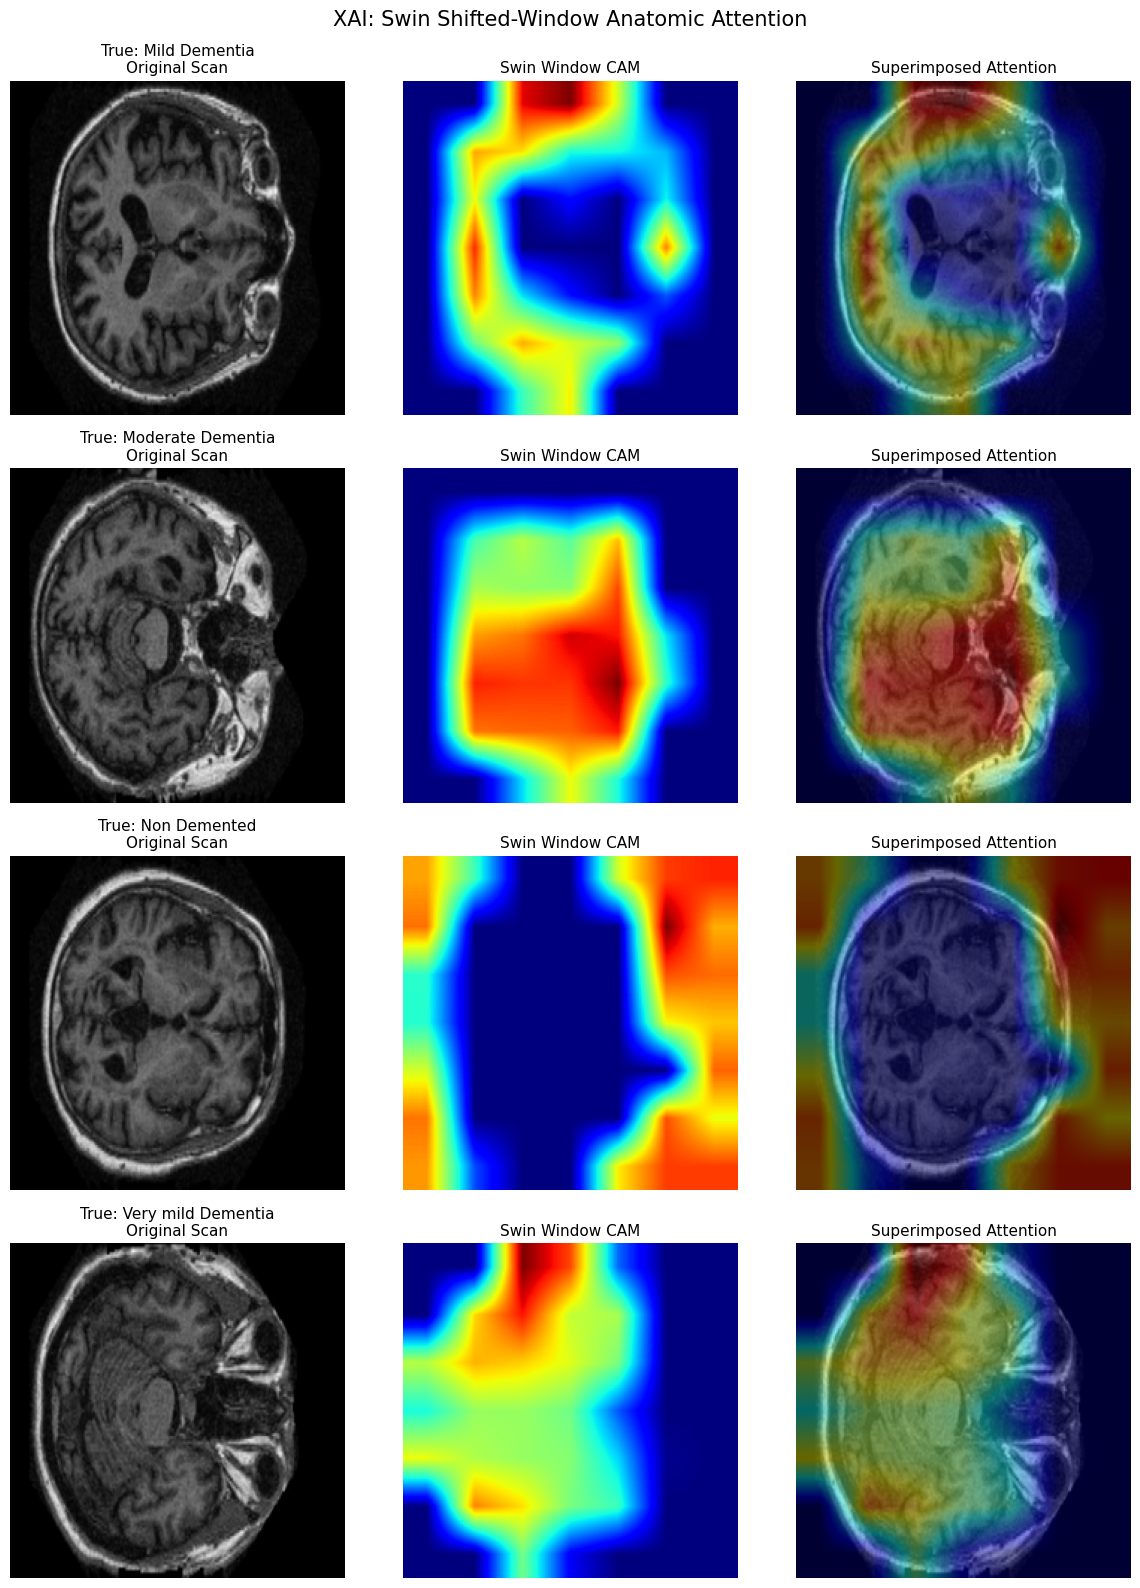

In [9]:
class SwinGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        # Swin stage output shape: [B, H, W, C]
        self.activations = output

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, target_class):
        self.model.eval()
        self.model.zero_grad()
        
        output = self.model(input_tensor)
        score = output[0, target_class]
        score.backward()

        # Channel-wise pooling of gradients
        weights = torch.mean(self.gradients, dim=(1, 2), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=-1).squeeze().cpu().detach().numpy()

        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (IMAGE_SIZE, IMAGE_SIZE))
        cam = (cam - np.min(cam)) / (np.max(cam) - np.min(cam) + 1e-8)
        return cam

# Target the final Stage 4 block of Swin Transformer
swin_grad_cam = SwinGradCAM(model, model.swin.features[7])

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for row_idx, cls_name in enumerate(target_classes):
    cls_test_indices = [idx for idx, y in enumerate(test_y) if y == row_idx]
    sample_path = test_paths[cls_test_indices[0]]
    
    raw_img = Image.open(sample_path).convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE))
    input_tensor = eval_transforms(raw_img).unsqueeze(0).to(device)
    
    heatmap = swin_grad_cam.generate_heatmap(input_tensor, target_class=row_idx)
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    
    overlay = np.float32(heatmap_colored) / 255 * 0.4 + np.float32(raw_img) / 255 * 0.6
    overlay = np.clip(overlay, 0, 1)

    axes[row_idx, 0].imshow(raw_img)
    axes[row_idx, 0].set_title(f"True: {cls_name}\nOriginal Scan", fontsize=11)
    axes[row_idx, 0].axis('off')

    axes[row_idx, 1].imshow(heatmap, cmap='jet')
    axes[row_idx, 1].set_title("Swin Window CAM", fontsize=11)
    axes[row_idx, 1].axis('off')

    axes[row_idx, 2].imshow(overlay)
    axes[row_idx, 2].set_title("Superimposed Attention", fontsize=11)
    axes[row_idx, 2].axis('off')

plt.suptitle("XAI: Swin Shifted-Window Anatomic Attention", fontsize=15, y=0.99)
plt.tight_layout()
plt.show()

In [14]:
import joblib

# ---------------------------------------------------------
# SAVING WITH JOBLIB
# ---------------------------------------------------------
# Move model to CPU to ensure cross-device compatibility
model.cpu()
model.eval()

# Dump the entire PyTorch object
joblib.dump(model, 'swin_classifier.joblib')
print("Swin Transformer saved successfully to 'swin_classifier.joblib'")

# Return model to the active device if you continue using it in this session
model.to(device)


# ---------------------------------------------------------
# LOADING WITH JOBLIB
# ---------------------------------------------------------
# Load the model object (requires the SwinClassifier class definition to be in memory)
loaded_swin_model = joblib.load('swin_classifier.joblib')

# Move to the target hardware device
loaded_swin_model = loaded_swin_model.to(device)
loaded_swin_model.eval()
print("Swin Transformer loaded successfully from 'swin_classifier.joblib'")

Swin Transformer saved successfully to 'swin_classifier.joblib'
Swin Transformer loaded successfully from 'swin_classifier.joblib'


In [16]:
import os

file_name = 'swin_classifier.joblib'

if os.path.exists(file_name):
    size_mb = os.path.getsize(file_name) / (1024 * 1024)
    print(f"✅ Model successfully saved! File size: {size_mb:.2f} MB")
else:
    print("❌ Model save nahi hua hai. Code wapas run karein.")

✅ Model successfully saved! File size: 105.94 MB
